# Getting Started with R and VS Code (Jupyter Notebook)

Visual Studio Code (VS Code) is a lightweight, free code editor that supports many programming languages, including R.
With the Jupyter extension, you can run R code in interactive "notebook" cells, similar to RStudio's R Markdown.

**Why use VS Code with Jupyter for R?**
- You can write code and explanations in the same file.
- Interactive execution lets you test code piece by piece.
- VS Code works well for multi-language projects (e.g., R + Python).

In this lesson we cover the core building blocks of the language: **assignment, data types, vectors, factors, lists, data frames, functions and getting help**.

In [1]:
# Notebook setup: wide, readable figures with an opaque white background.
# (Without the hook, base-R plots render with a transparent background and
#  the black axes/labels disappear on dark-themed notebook viewers.)
options(repr.plot.width = 10, repr.plot.height = 6, repr.plot.res = 100)
setHook("before.plot.new", function() par(bg = "white"))

In [2]:
# Simple R example in a Jupyter notebook
greeting <- function(name) {
  paste("Hello,", name, "! Welcome to R in VS Code")
}

greeting("Student")

[1] "Hello, Student ! Welcome to R in VS Code"

## 1. Assignment and Basic Data Types

R uses `<-` for assignment (`=` also works, but `<-` is the community convention).
Every value has a **type**, which you can inspect with `class()`:

| Type | Example | Notes |
|---|---|---|
| numeric | `3.14` | double-precision by default |
| integer | `5L` | the `L` suffix forces an integer |
| character | `"hello"` | strings |
| logical | `TRUE`, `FALSE` | result of comparisons |
| NA | `NA` | missing value (not the same as `NULL`) |

In [3]:
height <- 1.78      # numeric
age    <- 29L       # integer
city   <- "Ankara"  # character
adult  <- age >= 18 # logical

for (v in list(height, age, city, adult, NA)) {
  cat(sprintf("%-8s -> class: %s\n", format(v), class(v)))
}

1.78     -> class: numeric
29       -> class: integer
Ankara   -> class: character
TRUE     -> class: logical
NA       -> class: logical


## 2. Vectors: R's Fundamental Data Structure

A **vector** is an ordered collection of values of the *same type*. Even a single number is a vector of length 1.
Operations in R are **vectorised**: they apply element-wise without writing a loop.

$$
\mathbf{x} = (x_1, x_2, \dots, x_n), \qquad 2\mathbf{x} = (2x_1, 2x_2, \dots, 2x_n)
$$

Note that **R indexing starts at 1**, not 0 as in Python.

In [4]:
scores <- c(72, 85, 90, 64, 78)
names(scores) <- c("Ali", "Ayse", "Mehmet", "Zeynep", "Can")

print(scores)
cat("Length            :", length(scores), "\n")
cat("First element     :", scores[1], "\n")
cat("Elements 2 to 4   :", scores[2:4], "\n")
cat("By name (Ayse)    :", scores["Ayse"], "\n")
cat("Scores above 75   :", names(scores[scores > 75]), "\n")
cat("Curved (+5, max100):", pmin(scores + 5, 100), "\n")
cat("Mean / SD         :", round(mean(scores), 2), "/", round(sd(scores), 2), "\n")

   Ali   Ayse Mehmet Zeynep    Can 
    72     85     90     64     78 


Length            : 5 


First element     : 72 


Elements 2 to 4   : 85 90 64 


By name (Ayse)    : 85 


Scores above 75   : Ayse Mehmet Can 


Curved (+5, max100): 77 90 95 69 83 


Mean / SD         : 77.8 / 10.31 


*Insight: Mixing types in `c()` silently **coerces** everything to the most general type: `c(1, "a", TRUE)` becomes a character vector. This is the most common source of "why is my number a string?" bugs in R.*

In [5]:
mixed <- c(1, "a", TRUE)
print(mixed)
print(class(mixed))

[1] "1"    "a"    "TRUE"


[1] "character"


## 3. Factors: Categorical Data

A **factor** stores categorical data as integer codes plus a set of **levels**. Statistical functions (ANOVA, regression, plots) treat factors as groups, so getting factors right matters for every later lesson in this section.

In [6]:
blood <- factor(c("A", "B", "O", "A", "AB", "O", "O", "A", "B", "O"),
                levels = c("O", "A", "B", "AB"))
print(blood)
print(levels(blood))
print(table(blood))

# Ordered factors keep a meaningful order
satisfaction <- factor(c("low", "high", "medium", "high", "low"),
                       levels = c("low", "medium", "high"), ordered = TRUE)
print(satisfaction)
cat("Any response above 'medium'? ", any(satisfaction > "medium"), "\n")

 [1] A  B  O  A  AB O  O  A  B  O 
Levels: O A B AB


[1] "O"  "A"  "B"  "AB"


blood
 O  A  B AB 
 4  3  2  1 


[1] low    high   medium high   low   
Levels: low < medium < high


Any response above 'medium'?  TRUE 


## 4. Lists and Data Frames

* A **list** can hold elements of *different* types and lengths (like a Python dict).
* A **data frame** is a list of equal-length vectors — the R equivalent of a spreadsheet or a pandas DataFrame. Each column has one type; each row is an observation.

In [7]:
student <- list(name = "Ayse", age = 22L, courses = c("Stats", "R", "Calculus"))
str(student)
cat("Second course:", student$courses[2], "\n\n")

df <- data.frame(
  name  = names(scores),
  score = unname(scores),
  group = factor(c("A", "B", "A", "B", "A"))
)
print(df)
cat("\nStructure:\n"); str(df)
cat("\nRows with score > 75:\n"); print(df[df$score > 75, ])
cat("\nMean score by group:\n"); print(aggregate(score ~ group, data = df, FUN = mean))

List of 3
 $ name   : chr "Ayse"
 $ age    : int 22
 $ courses: chr [1:3] "Stats" "R" "Calculus"


Second course: R 



    name score group
1    Ali    72     A
2   Ayse    85     B
3 Mehmet    90     A
4 Zeynep    64     B
5    Can    78     A



Structure:


'data.frame':	5 obs. of  3 variables:
 $ name : chr  "Ali" "Ayse" "Mehmet" "Zeynep" ...
 $ score: num  72 85 90 64 78
 $ group: Factor w/ 2 levels "A","B": 1 2 1 2 1



Rows with score > 75:


    name score group
2   Ayse    85     B
3 Mehmet    90     A
5    Can    78     A



Mean score by group:


  group score
1     A  80.0
2     B  74.5


## 5. Getting Help and Exploring Objects

| Command | What it does |
|---|---|
| `?mean` or `help(mean)` | open the documentation page |
| `example(mean)` | run the examples from the help page |
| `str(x)` | compact structure of any object |
| `summary(x)` | quick statistical summary |
| `ls()` | list objects in your workspace |

In [8]:
summary(df)

     name               score      group
 Length:5           Min.   :64.0   A:3  
 Class :character   1st Qu.:72.0   B:2  
 Mode  :character   Median :78.0        
                    Mean   :77.8        
                    3rd Qu.:85.0        
                    Max.   :90.0        

## 6. A First Visualisation

Base R can plot directly from vectors and factors. Below: the blood-type factor as a bar chart, and the student scores against the class mean.

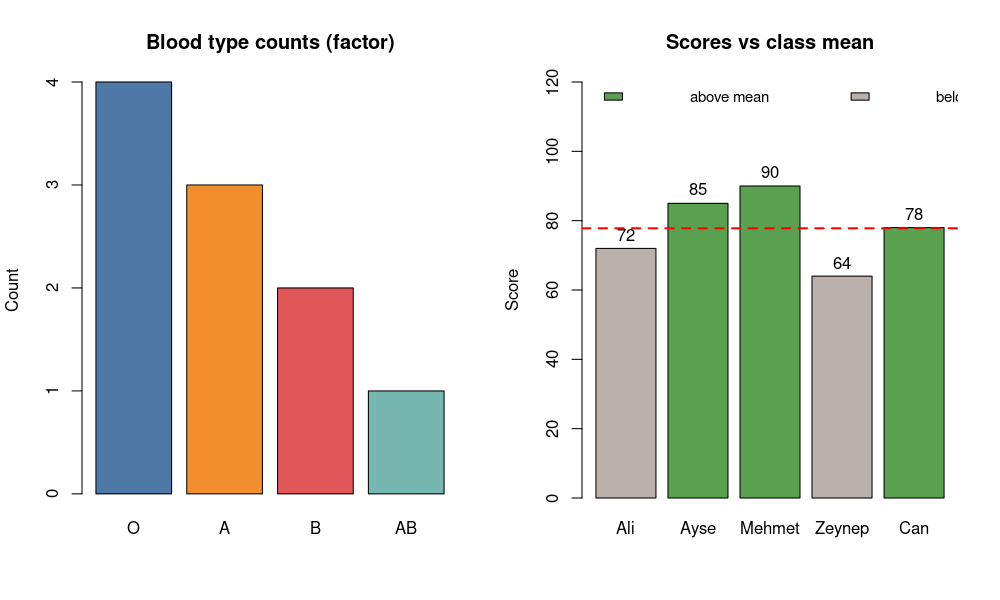

In [9]:
par(mfrow = c(1, 2))
barplot(table(blood), col = c("#4E79A7", "#F28E2B", "#E15759", "#76B7B2"),
        main = "Blood type counts (factor)", ylab = "Count")

bp <- barplot(df$score, names.arg = df$name, col = ifelse(df$score > mean(df$score), "#59A14F", "#BAB0AC"),
              ylim = c(0, 120), main = "Scores vs class mean", ylab = "Score")
abline(h = mean(df$score), col = "red", lwd = 2, lty = 2)
text(bp, df$score + 4, df$score)
legend("topleft", c("above mean", "below mean", "class mean"), horiz = TRUE, cex = 0.9,
       fill = c("#59A14F", "#BAB0AC", NA), border = c("black", "black", NA),
       lty = c(NA, NA, 2), col = c(NA, NA, "red"), bty = "n")

*Insight: Notice that we never wrote a loop. Filtering (`scores > 75`), arithmetic (`scores + 5`) and grouping (`aggregate`) all work on whole vectors at once. Thinking in vectors instead of loops is the single biggest mindset shift when learning R.*

## Real-World Use Case or Analogy

Think of R's data structures as **office supplies for a teacher**:

* A **vector** is one row of a grade book: all the scores of one exam, same type, in order.
* A **factor** is the colour-coded sticker you put on each student ("Group A", "Group B") — a label from a fixed set.
* A **list** is a student's file folder: a name, an age, a list of courses, all of different shapes.
* A **data frame** is the full grade-book spreadsheet: one row per student, one typed column per attribute.

Every statistical method in the rest of this section consumes one of these four structures, so being comfortable with them now pays off in every later lesson.